# Phase 1 – Part B: Supervised Learning

## Random Forest


## 1. Model Selection Rationale

Random Forest was selected because it is a tree-based ensemble model that combines multiple decision trees to improve prediction performance. It can capture non-linear relationships between health indicators and diabetes risk and is suitable for structured tabular data. Random Forest does not require feature scaling because tree-based models split data using feature thresholds.


## 2. Data Preparation

The preprocessed training and testing datasets were used. The target variable is `Diabetes_binary`, and the remaining 21 health indicators were used as input features. The same train/test split was used for the supervised learning models to ensure a fair comparison.


### Dataset Loading

The training and testing datasets are loaded directly from the project GitHub repository, so the notebook does not require manual file uploads in Google Colab.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

for d in ["models", "evaluation_results", "plots"]:
    os.makedirs(d, exist_ok=True)

In [4]:
# Load the training and testing datasets

DATA_DIR = "../Dataset"

train_df = pd.read_csv(f"{DATA_DIR}/train_data.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test_data.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nFirst five rows of training data:")
display(train_df.head())

Training shape: (55245, 22)
Testing shape: (13812, 22)

First five rows of training data:


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1.0,1.0,1.0,40.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,4.0,21.0,14.0,0.0,0.0,7.0,5.0,7.0,1.0
1,1.0,1.0,1.0,47.0,1.0,0.0,1.0,0.0,1.0,1.0,...,1.0,3.0,30.0,14.0,1.0,0.0,6.0,3.0,1.0,1.0
2,0.0,0.0,1.0,24.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,2.0,3.0,0.0,0.0,0.0,7.0,5.0,7.0,0.0
3,1.0,1.0,1.0,42.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,3.0,0.0,0.0,0.0,0.0,9.0,5.0,7.0,1.0
4,0.0,0.0,1.0,35.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,3.0,6.0,0.0,1.0,0.0,9.0,5.0,6.0,1.0


In [24]:
TARGET = "Diabetes_binary"

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]

X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (55245, 21)
y_train: (55245,)
X_test: (13812, 21)
y_test: (13812,)


Dataset Overview

The training set contains 55,245 records and the testing set contains 13,812 records. There are 21 input features and one binary target variable, `Diabetes_binary`.

The target distribution in the training data is relatively balanced, with both classes represented at similar proportions. This supports using standard classification metrics such as Accuracy, Precision, Recall, F1-score, and ROC-AUC.


In [25]:
# Display basic information about the prepared dataset
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nClass distribution in training data:")
print(train_df["Diabetes_binary"].value_counts(normalize=True))

print("\nNumber of features:", train_df.shape[1] - 1)


Training shape: (55245, 22)
Testing shape: (13812, 22)

Class distribution in training data:
Diabetes_binary
1.0    0.508227
0.0    0.491773
Name: proportion, dtype: float64

Number of features: 21


## 3. Model Training

A baseline Random Forest model was trained using 100 decision trees. The trained model was then used to predict the class labels and probabilities for the test set.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train the baseline Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)


Random Forest training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict the test data
y_pred = rf_model.predict(X_test)

# Predict probabilities for the positive class
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.7303
Precision: 0.7157
Recall:    0.7786
F1-score:  0.7459
ROC-AUC:   0.7982


## 4. Model Evaluation

The baseline Random Forest model was evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, and the Confusion Matrix.


The baseline Random Forest confusion matrix shows the number of correct and incorrect predictions for each class.


[[4621 2171]
 [1554 5466]]


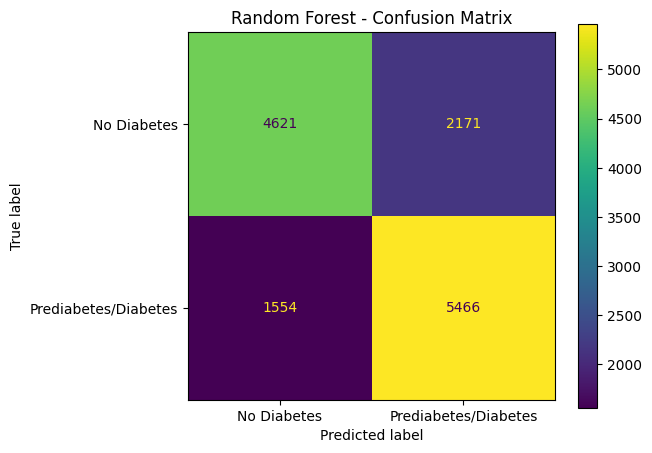

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Prediabetes/Diabetes"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

The baseline Random Forest model correctly classified 4,621 negative cases (TN) and 5,466 positive cases (TP). It produced 2,171 false positives (FP) and 1,554 false negatives (FN). The false negatives represent positive cases that the model failed to identify, which is an important consideration in a clinical screening application.


Feature importance was extracted to identify which health indicators contributed most to the baseline Random Forest model's predictions.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 Important Features:")
print(importance.head(10))

Top 10 Important Features:
BMI          0.169321
Age          0.127698
GenHlth      0.102325
Income       0.084722
HighBP       0.075560
PhysHlth     0.068696
Education    0.057904
MentHlth     0.052424
HighChol     0.040297
Fruits       0.029372
dtype: float64


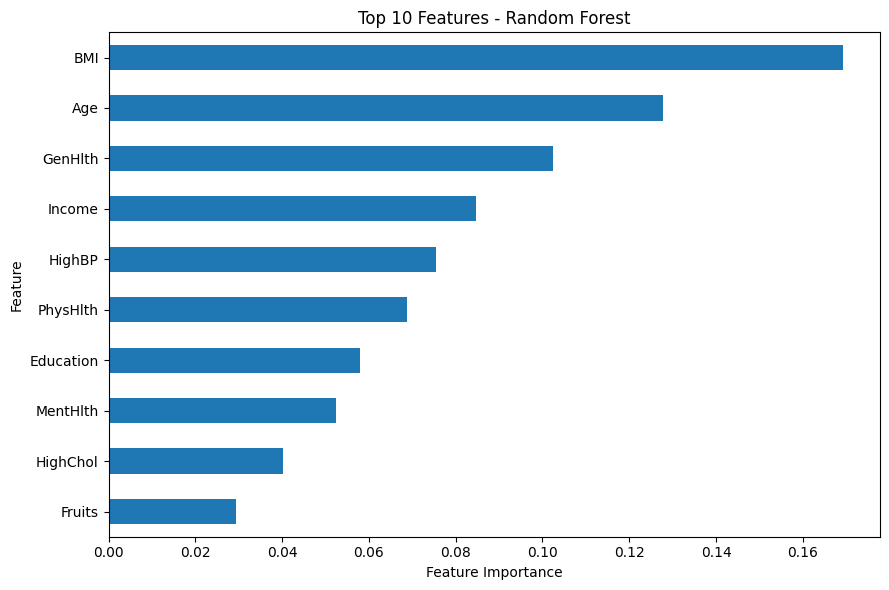

In [ ]:
importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 10 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 5. Cross-Validation

A 5-fold cross-validation was applied to the baseline Random Forest model to evaluate its stability across different subsets of the training data. Multiple evaluation metrics were used so that the model was not judged using F1-score alone.


In [26]:
from sklearn.model_selection import cross_validate

# Evaluate baseline Random Forest stability using 5-fold cross-validation
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_results = cross_validate(
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

for metric in scoring:
    print(metric, cv_results[f"test_{metric}"].mean())


accuracy 0.7309258756448548
precision 0.7187340669321196
recall 0.7730881300850134
f1 0.7449178124197883
roc_auc 0.80095275861112


## 6. Hyperparameter Tuning

RandomizedSearchCV with 5-fold cross-validation was used to tune the Random Forest hyperparameters based on the F1-score. Eight hyperparameter combinations were evaluated.


In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_dist,
    n_iter=8,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

rf_model = random_search.best_estimator_

print("Best parameters:", random_search.best_params_)
print("Best cross-validation F1:", random_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 10}
Best cross-validation F1: 0.7619477372307131


RandomizedSearchCV identified the following configuration as the best combination based on the F1-score:

- `n_estimators = 100`
- `max_depth = 10`
- `min_samples_split = 2`
- `min_samples_leaf = 1`

The best cross-validation F1-score was approximately 0.762.


Hyperparameter Tuning Results

RandomizedSearchCV identified the following configuration as the best combination based on the F1-score:

- `n_estimators = 100`
- `max_depth = 10`
- `min_samples_split = 2`
- `min_samples_leaf = 1`

The best cross-validation F1-score was approximately 0.762. This result provides the basis for evaluating the tuned model on the unseen test set.


## 8. Tuned Model Evaluation

The best Random Forest model selected by RandomizedSearchCV was evaluated on the unseen test set using Accuracy, Precision, Recall, F1-score, ROC-AUC, and the Confusion Matrix.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predictions using the tuned Random Forest model
y_pred_tuned = rf_model.predict(X_test)
y_prob_tuned = rf_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred_tuned)
precision = precision_score(y_test, y_pred_tuned)
recall = recall_score(y_test, y_pred_tuned)
f1 = f1_score(y_test, y_pred_tuned)
roc_auc = roc_auc_score(y_test, y_prob_tuned)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Accuracy:  0.7454
Precision: 0.7278
Recall:    0.7973
F1-score:  0.7610
ROC-AUC:   0.8198

Confusion Matrix:
[[4699 2093]
 [1423 5597]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.77      0.69      0.73      6792
         1.0       0.73      0.80      0.76      7020

    accuracy                           0.75     13812
   macro avg       0.75      0.74      0.74     13812
weighted avg       0.75      0.75      0.74     13812



In [29]:
from sklearn.ensemble import RandomForestClassifier

# Recreate the baseline Random Forest
baseline_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

baseline_model.fit(X_train, y_train)

# Baseline predictions
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Baseline model recreated successfully!")

Baseline model recreated successfully!


## 8. Baseline vs Tuned Model Comparison

The baseline and tuned Random Forest models are compared using the same test-set metrics. This shows whether hyperparameter tuning produced a meaningful improvement rather than relying only on the best cross-validation score.


In [33]:
# Tuned model predictions

y_pred_tuned = rf_model.predict(X_test)
y_prob_tuned = rf_model.predict_proba(X_test)[:, 1]

print("Tuned model predictions created successfully!")

Tuned model predictions created successfully!


In [34]:
# Compare baseline and tuned Random Forest performance
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Baseline": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ],
    "Tuned": [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_tuned),
        roc_auc_score(y_test, y_prob_tuned)
    ]
})

comparison["Change"] = comparison["Tuned"] - comparison["Baseline"]

comparison


,Metric,Baseline,Tuned,Change
0,Accuracy,0.730307,0.745439,0.015132
1,Precision,0.715726,0.727828,0.012102
2,Recall,0.778632,0.797293,0.018661
3,F1-score,0.745855,0.760979,0.015124
4,ROC-AUC,0.798239,0.819802,0.021563


The comparison should be interpreted together with the cross-validation results. A positive change indicates an improvement after tuning, while a value close to zero indicates that the baseline model was already performing similarly.


## 9. Confusion Matrix — Tuned Random Forest

The tuned Random Forest confusion matrix shows the number of correct and incorrect predictions for each class.


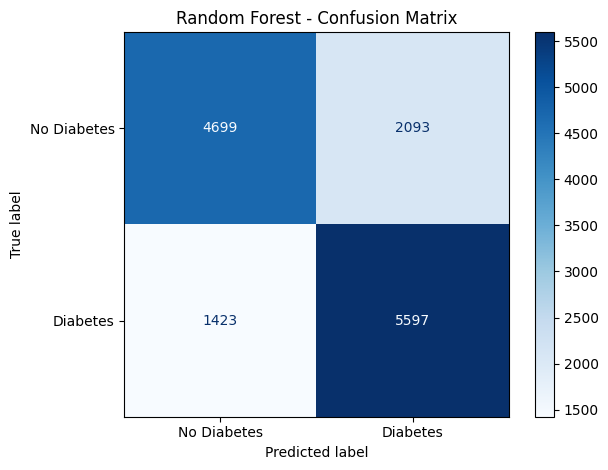

In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("plots", exist_ok=True)

cm = confusion_matrix(y_test, y_pred_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig("plots/random_forest_confusion_matrix.png", dpi=300)
plt.show()

The tuned Random Forest model correctly classified 4,699 negative cases (TN) and 5,597 positive cases (TP). It produced 2,093 false positives (FP) and 1,423 false negatives (FN). The false negatives represent positive cases that the model failed to identify, which is particularly important in a healthcare screening context.


## 10. Misclassification Analysis

False negatives are particularly important in a healthcare screening context because they represent positive cases that were incorrectly classified as negative. Therefore, recall is an important metric alongside accuracy and F1-score.


In [35]:
# Extract confusion matrix values
cm = confusion_matrix(y_test, y_pred_tuned)
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Compare false negative cases with correctly detected positive cases
errors = X_test.copy()
errors["y_true"] = y_test.values
errors["y_pred"] = y_pred_tuned

fn_cases = errors[
    (errors["y_true"] == 1) &
    (errors["y_pred"] == 0)
]

tp_cases = errors[
    (errors["y_true"] == 1) &
    (errors["y_pred"] == 1)
]

fn_vs_tp = pd.DataFrame({
    "FN_mean": fn_cases[X_test.columns].mean(),
    "TP_mean": tp_cases[X_test.columns].mean()
})

fn_vs_tp["Difference"] = fn_vs_tp["FN_mean"] - fn_vs_tp["TP_mean"]

fn_vs_tp = fn_vs_tp.reindex(
    fn_vs_tp["Difference"].abs().sort_values(ascending=False).index
)

fn_vs_tp.head(10)


True Negatives: 4699
False Positives: 2093
False Negatives: 1423
True Positives: 5597


,FN_mean,TP_mean,Difference
PhysHlth,2.908644,9.328926,-6.420282
BMI,28.107519,32.684831,-4.577312
MentHlth,2.316936,4.991603,-2.674667
Income,6.161630,4.976059,1.185572
GenHlth,2.390021,3.511881,-1.121860
Age,8.520028,9.605324,-1.085296
HighBP,0.338721,0.863498,-0.524777
Education,5.106114,4.663391,0.442723
DiffWalk,0.077301,0.453279,-0.375977
HighChol,0.387913,0.736823,-0.348910


The misclassification analysis helps identify which feature patterns differ between missed positive cases and correctly detected positive cases. These differences describe model behavior and should not be interpreted as causal relationships.


## 11. ROC Curve — Tuned Random Forest

The ROC curve illustrates the trade-off between the true positive rate and the false positive rate across different classification thresholds. The ROC-AUC value summarizes the model's ability to distinguish between the two target classes.


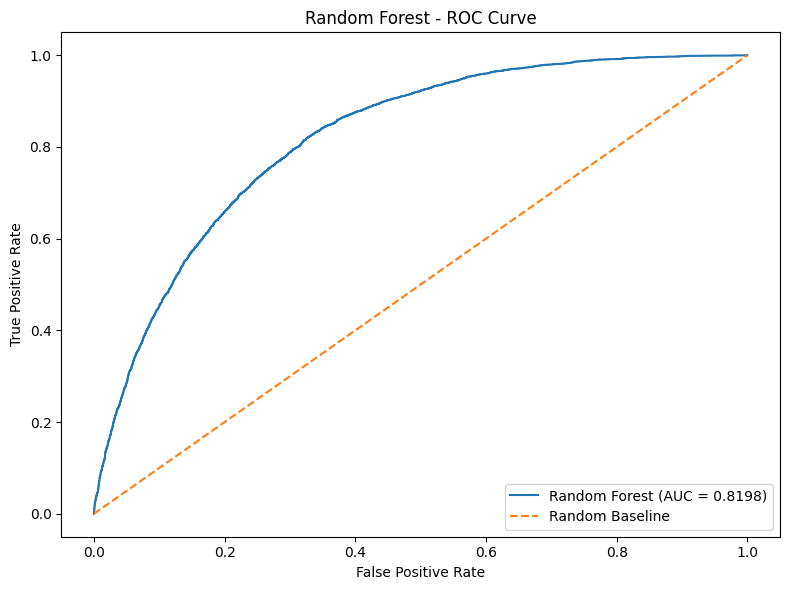

ROC-AUC: 0.8198


In [36]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import os

os.makedirs("plots", exist_ok=True)

fpr, tpr, thresholds = roc_curve(y_test, y_prob_tuned)
roc_auc = roc_auc_score(y_test, y_prob_tuned)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("plots/random_forest_roc_curve.png", dpi=300)
plt.show()

print("ROC-AUC:", round(roc_auc, 4))

The tuned Random Forest model achieved a ROC-AUC score of approximately 0.82, indicating a good ability to distinguish between the two target classes.


The ROC-AUC value of approximately 0.82 indicates that the tuned Random Forest has a good ability to distinguish between the two target classes. The ROC curve also shows the trade-off between detecting positive cases and producing false positives as the classification threshold changes.


## 12. Feature Importance — Tuned Random Forest

The feature importance values of the tuned Random Forest model were extracted to identify which health indicators contributed most to the model's predictions.


             Feature  Importance
             GenHlth    0.216487
              HighBP    0.210909
                 BMI    0.141067
                 Age    0.101857
            HighChol    0.093753
            DiffWalk    0.047339
              Income    0.031848
            PhysHlth    0.031730
HeartDiseaseorAttack    0.028668
           Education    0.016197


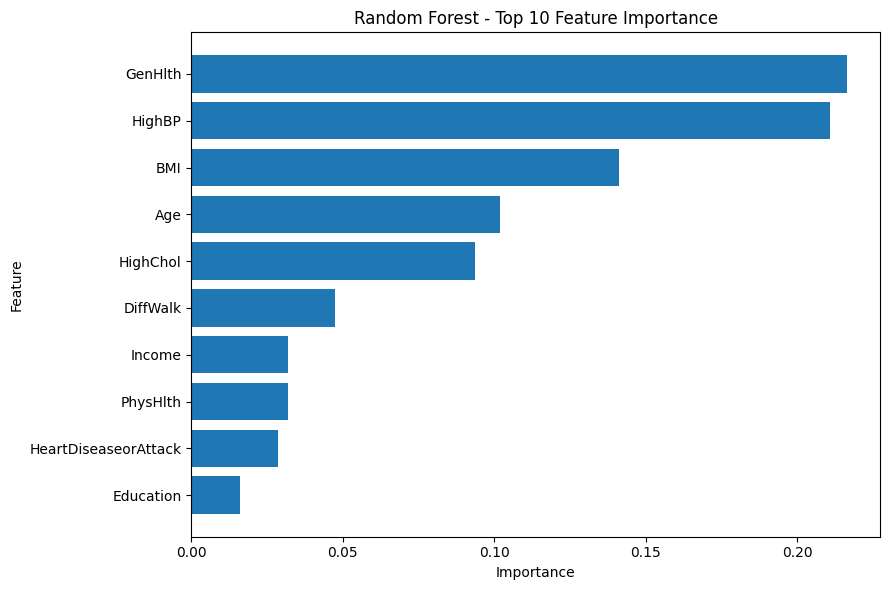

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("plots", exist_ok=True)
os.makedirs("evaluation_results", exist_ok=True)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(10).to_string(index=False))

# Save all feature importance values
feature_importance.to_csv(
    "evaluation_results/feature_importance.csv",
    index=False
)

# Plot top 10 features
top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Top 10 Feature Importance")
plt.tight_layout()

plt.savefig(
    "plots/random_forest_feature_importance.png",
    dpi=300
)
plt.show()

The feature importance analysis identifies the features the Random Forest relied on most when making predictions. Feature importance reflects the contribution of a feature to the model's predictions and does not establish a causal relationship with diabetes.


The feature importance ranking identifies which health indicators contributed most to the Random Forest predictions. The top features include BMI, Age, GenHlth, Income, HighBP, and PhysHlth.

These values describe how the model uses the features for prediction and do not establish that a feature causes diabetes. A feature with higher importance is simply more useful to the trained model under this dataset and modeling approach.


## 13. Final Interpretation

The tuned Random Forest model achieved approximately 74.5% accuracy, 72.8% precision, 79.7% recall, 76.1% F1-score, and 0.82 ROC-AUC on the test set.

Compared with the baseline Random Forest model, the tuned model improved the overall test-set performance. The baseline-versus-tuned comparison above shows the exact change in each metric.

The confusion matrix shows that the tuned model correctly classified 4,699 negative cases and 5,597 positive cases, while producing 2,093 false positives and 1,423 false negatives. Because false negatives represent positive cases missed by the model, recall is particularly important in a healthcare screening context.

The feature importance analysis identifies the health indicators that were most useful to the model for prediction. These results explain model behavior but should not be interpreted as evidence of causation.

The final model should be compared with Logistic Regression and XGBoost using the same evaluation criteria before selecting the final supervised learning model.


## 14. Strengths and Limitations

**Strengths:** Captures complex non-linear relationships, handles interactions between health indicators, works well with structured tabular data, and provides feature importance for model interpretation.

**Limitations:** Less directly interpretable than Logistic Regression, can require more computational resources, and can still produce false positives and false negatives. Feature importance describes model behavior and does not establish causal relationships with diabetes.


## 15. Conclusion

The tuned Random Forest model achieved approximately 74.5% accuracy, 76.1% F1-score, and 0.82 ROC-AUC on the test set.

Hyperparameter tuning improved the Random Forest's test-set performance compared with the baseline model. The model also provides feature-importance information and can capture non-linear relationships that linear models may not capture as effectively.

The final model selection will be determined after comparing Random Forest with Logistic Regression and XGBoost using the same evaluation metrics and considering the requirements of the healthcare classification task.


## 16. Save Model and Results

The trained model, evaluation results, feature importance values, and visualization files were saved for submission and comparison with the other supervised learning models.


In [ ]:
import os
import json
import joblib
import shutil
import zipfile
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create required folders
os.makedirs("models", exist_ok=True)
os.makedirs("evaluation_results", exist_ok=True)
os.makedirs("plots", exist_ok=True)

# Save the trained model
joblib.dump(rf_model, "models/random_forest_model.joblib")

# Save evaluation metrics
metrics = {
    "Model": "Random Forest",
    "Best Parameters": random_search.best_params_,
    "Best CV F1": random_search.best_score_,
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned),
    "Recall": recall_score(y_test, y_pred_tuned),
    "F1-score": f1_score(y_test, y_pred_tuned),
    "ROC-AUC": roc_auc_score(y_test, y_prob_tuned)
}

pd.DataFrame([metrics]).to_csv(
    "evaluation_results/random_forest_results.csv",
    index=False
)

# Save best parameters separately
with open("evaluation_results/best_parameters.json", "w") as f:
    json.dump(random_search.best_params_, f, indent=4)

# Prepare a clean ZIP containing only deliverables
files_to_zip = [
    "models/random_forest_model.joblib",
    "evaluation_results/random_forest_results.csv",
    "evaluation_results/feature_importance.csv",
    "evaluation_results/best_parameters.json",
    "plots/random_forest_confusion_matrix.png",
    "plots/random_forest_roc_curve.png",
    "plots/random_forest_feature_importance.png"
]

missing_files = [f for f in files_to_zip if not os.path.exists(f)]

if missing_files:
    print("Missing files:")
    for f in missing_files:
        print("-", f)
else:
    zip_name = "random_forest_submission.zip"

    with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
        for file in files_to_zip:
            z.write(file)

    print("ZIP created successfully!")
    print("\nFiles included:")
    with zipfile.ZipFile(zip_name, "r") as z:
        for name in z.namelist():
            print("-", name)

ZIP created successfully!

Files included:
- models/random_forest_model.joblib
- evaluation_results/random_forest_results.csv
- evaluation_results/feature_importance.csv
- evaluation_results/best_parameters.json
- plots/random_forest_confusion_matrix.png
- plots/random_forest_roc_curve.png
- plots/random_forest_feature_importance.png
